# 93장 · 서비스 상태와 종료 조건

상태 전이표는 입력과 현재 상태에 따라 다음 작업이나 종료 위치가 어떻게 정해지는지 나타냅니다.

Q03의 오답은 자료를 더 모으기 전에 막을 수 있습니다. 어느 단계가 질문을 읽고, 어느 단계가 출처를 붙이며, 언제 흐름을 끝낼지 응답 한 건을 놓고 설계해 봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.


## next_step()의 상태 전이

설계안　질문 수신 → 빈 입력 검사 → 장비나 질문 목적 확인 → 허용 문서 검색 → 답과 출처 표시. 공백 질문이면 invalid_input에서, 장비를 특정하기 어려우면 need_clarification에서 끝냅니다. 문서에 없는 교체 일정은 no_evidence로 마칩니다. 검색 결과가 있을 때만 answered로 원문 위치를 보냅니다. 인증·모델·외부 도구는 이 로컬 규칙을 구현하는 데 필요하지 않습니다.

<!-- lesson-visual visual-roles -->
**질문을 읽는 순서에 따라 다음 상태 고르기**

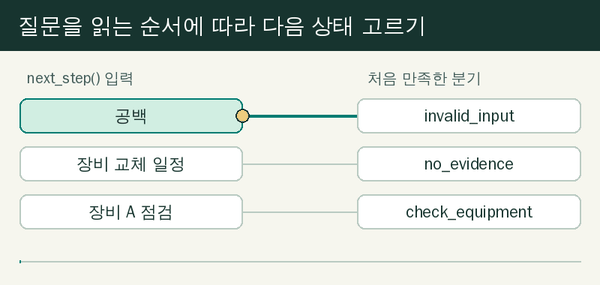

빈 문자열은 첫 검사에서 종료합니다. 교체나 일정이 포함되면 no_evidence, 두 조건에 모두 걸리지 않으면 check_equipment로 갑니다.
<!-- /lesson-visual visual-roles -->


### 셀 01 · next_step()의 종료 상태

정해 둔 일정 질문을 넣었을 때 자료를 읽는 단계까지 가는지 예측하세요.

no_evidence는 여기서 사용자에게 근거 부족을 안내하고 끝낼 수 있는 상태입니다. check_equipment는 다음 함수로 보낼 내부 단계 이름입니다. 화면에 check_equipment라는 문자열을 최종 답으로 표시하지 않습니다.


In [1]:
def next_step(question):
    if not question.strip():
        return "invalid_input"
    if "교체" in question or "일정" in question:
        return "no_evidence"
    return "check_equipment"

print(next_step("장비 A를 다음 달에 교체하기로 확정했나요?"))

no_evidence


no_evidence에서 멈춥니다. 이 분기는 가상 규정에 일정이 없다는 현재 전제를 코드에 옮긴 것입니다. 일정표가 생기면 분기 자체를 다시 검토해야 합니다.


## 답변·출처 필드와 화면 상태 연결

응답 설계 예시　입력 Q01 / 검색어 장비 A / 후보 RULE-A / 본문 점검 전 전원 표시등을 확인합니다. / 표시할 위치 가상 장비실 규정 A, 1쪽 2.1절, 2026-11-01 / 문서판 rules-v1. 저장을 붙이는 팀은 답을 받는 단계와 저장 성공 여부를 분리하세요. 저장 실패 때문에 근거 없는 질문으로 보이면 사용자 행동이 달라집니다.


### Q01 응답 설계에서 검색 뒤 화면으로 넘어가는 값

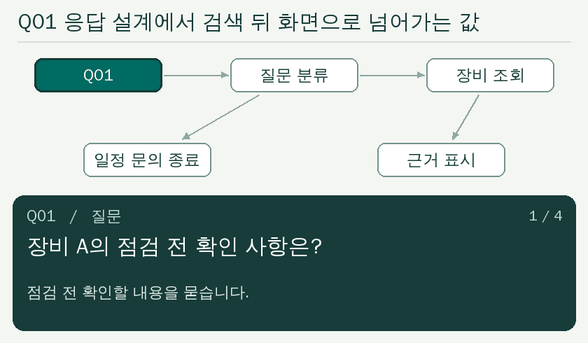

이 절의 서비스 설계 예시입니다. 앞 셀의 next_step()이 check_equipment를 반환한 뒤 붙일 검색과 응답 단계를 읽어 보세요.


### 과제 02 · 선택 연습 · 빈 입력의 상태 전이

공백만 넣었을 때 짧은 분기의 종료 위치를 표시하세요. 질문을 더 받으면 되는 상태와 구분해 봅니다.


In [2]:
# next_step을 호출하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(next_step(&quot;   &quot;))</code></pre>
<p>실행 결과</p><pre><code>invalid_input</code></pre>
<p>invalid_input을 돌려줍니다. 여기서 멈추면 자료를 읽는 비용도 생기지 않습니다.</p>
</details>


## 돌아보기

94장에는 검색기가 받아야 할 필드와 응답에 남길 필드를 적어 넘깁니다. 화면·저장 방식이 달라도 문서 ID와 버전으로 같은 근거를 가리킬 수 있어야 합니다.
